# 01 — EDA: Smart CI Test Prioritization (LRTS)

Thin notebook: every number and figure is produced by `src/stp/eda/*` (each section writes `reports/figures/*.png` and `reports/eda_json/*.json`). Prerequisites: `python -m stp.data.download` and `python -m stp.data.build_tables`. The written findings are in `reports/EDA_REPORT.md`.

In [1]:
import json
from IPython.display import Image, display, Markdown
import pandas as pd
from stp import paths
from stp.eda import a_baselines, b_costs, c_shape, d_failures, e_changes, f_signal, g_ttff, h_split
pd.set_option('display.width', 200)

def show(*names):
    for n in names:
        display(Image(filename=str(paths.FIGURES / f'{n}.png')))

## Audits
Count cross-checks (see `src/stp/data/audit.py`).

In [2]:
audit = json.loads((paths.EDA_JSON / 'audit.json').read_text())
display(pd.DataFrame(audit['test_files']['pass_fail_count_match']))
display(pd.DataFrame(audit['first_time_failure']['per_project']))
display(pd.DataFrame(audit['changes']['vs_change_stats_csv']))

,project,left_only,right_only,matched_rows,all_equal,match_rate
0,activemq,0,0,446,446,1.00000
1,hadoop,0,0,1980,1980,1.00000
2,hbase,0,0,1018,1018,1.00000
3,hive,0,0,2131,2131,1.00000
4,jackrabbit-oak,0,0,1654,1654,1.00000
5,james,0,0,5838,5838,1.00000
6,kafka,8,0,53546,53546,1.00000
7,karaf,0,0,726,726,1.00000
8,log4j,0,0,528,528,1.00000
9,tvm,0,0,40491,13658,0.33731


,project,runs,count_agree,lrts_ftf_rows,my_ftf_paper_rows,my_ftf_full_history_rows,lrts_ftf_runs,my_ftf_runs,run_flag_agree
0,activemq,207,1.000000,137.0,137.0,137.0,44,44,1.000000
1,hadoop,1299,1.000000,1020.0,1020.0,1020.0,159,159,1.000000
2,hbase,553,1.000000,201.0,201.0,201.0,126,126,1.000000
3,hive,2056,1.000000,700.0,700.0,700.0,136,136,1.000000
4,jackrabbit-oak,860,0.998837,811.0,812.0,812.0,119,119,1.000000
5,james,3147,1.000000,910.0,910.0,910.0,259,259,1.000000
6,kafka,39006,0.999769,5947.0,5934.0,5934.0,1948,1942,0.999795
7,karaf,620,1.000000,55.0,55.0,55.0,37,37,1.000000
8,log4j,528,1.000000,127.0,127.0,127.0,59,59,1.000000
9,tvm,9161,1.000000,1240.0,1240.0,1240.0,387,387,1.000000


,project,left_only,right_only,matched_rows,all_equal,match_rate
0,activemq,239,0,207,207,1.000000
1,hadoop,681,0,1299,1299,1.000000
2,hbase,207,0,278,278,1.000000
3,hive,75,0,2056,2056,1.000000
4,jackrabbit-oak,794,0,860,860,1.000000
5,james,1949,0,2404,2404,1.000000
6,kafka,4245,0,11843,11843,1.000000
7,karaf,106,0,620,620,1.000000
8,log4j,0,0,270,270,1.000000
9,tvm,5094,0,1418,1412,0.995769


## A. Motivation: paper baselines (APFDc, macro over projects)

In [3]:
s = a_baselines.run()
pd.DataFrame({v: {t: s[v]['mean_apfdc'][t]['macro'] for t in a_baselines.TECHNIQUES} for v in ['All','DeConf','FirstFail']}).round(3)

,All,DeConf,FirstFail
Random,0.502,0.502,0.504
QTF,0.677,0.739,0.798
LastFail_Asc,0.795,0.735,0.467
FailCount_Desc,0.720,0.613,0.312
TestFile_FailFreq,0.666,0.627,0.440
IR_GitDiff,0.576,0.633,0.667
IR_GitDiff_tfidf,0.589,0.647,0.691
ML_f1,0.724,0.614,0.292
ML_f3,0.548,0.593,0.681
ML_fall,0.764,0.736,0.562


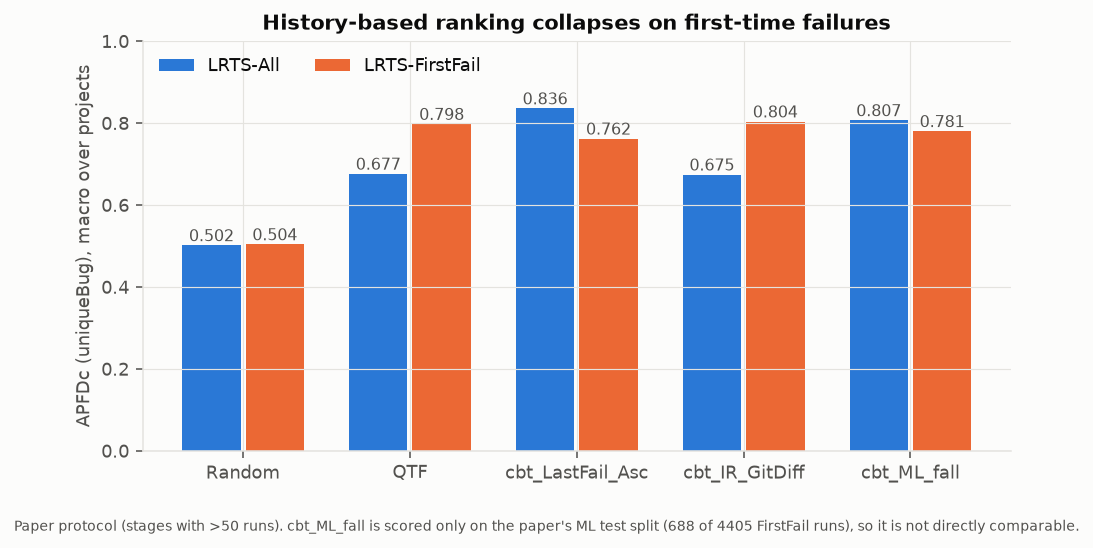

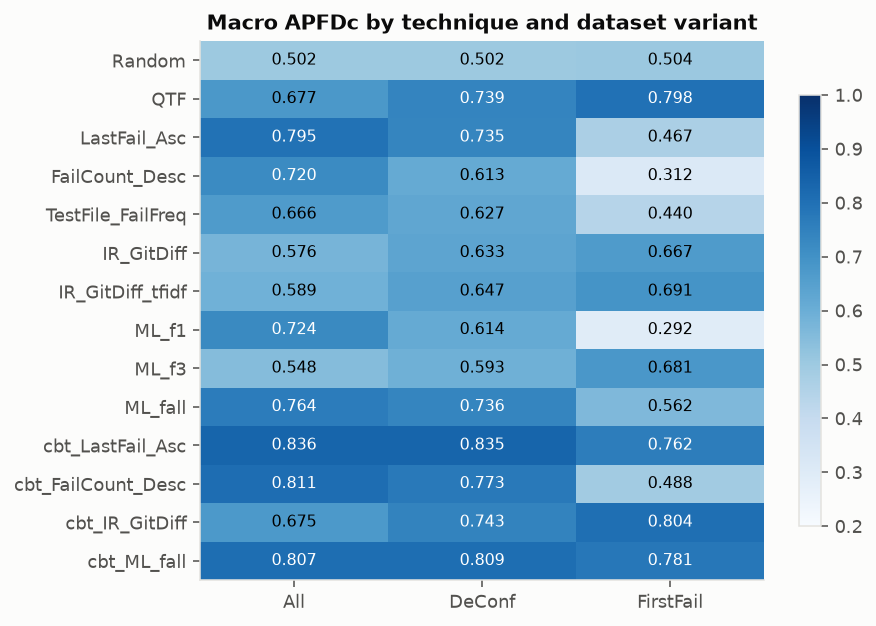

In [4]:
show('A_headline_all_vs_firstfail', 'A_macro_table')

## B. The problem is real: costs

In [5]:
s = b_costs.run()
pd.DataFrame({k: s['full'][k]['per_project'] for k in ['duration_h_median','share_runs_over_1h','share_runs_over_2h','share_runs_over_6h','classes_per_run_median']}).round(3)

,duration_h_median,share_runs_over_1h,share_runs_over_2h,share_runs_over_6h,classes_per_run_median
activemq,5.541,0.935,0.877,0.265,1009.0
hadoop,0.813,0.494,0.410,0.287,533.0
hbase,10.482,0.834,0.828,0.823,1217.0
hive,27.561,0.998,0.998,0.994,1361.0
jackrabbit-oak,3.157,0.943,0.900,0.000,1991.0
james,2.763,0.855,0.704,0.118,2145.0
kafka,6.790,0.868,0.868,0.593,1264.0
karaf,0.297,0.028,0.015,0.003,218.0
log4j,0.217,0.000,0.000,0.000,651.0
tvm,4.242,0.741,0.645,0.354,257.0


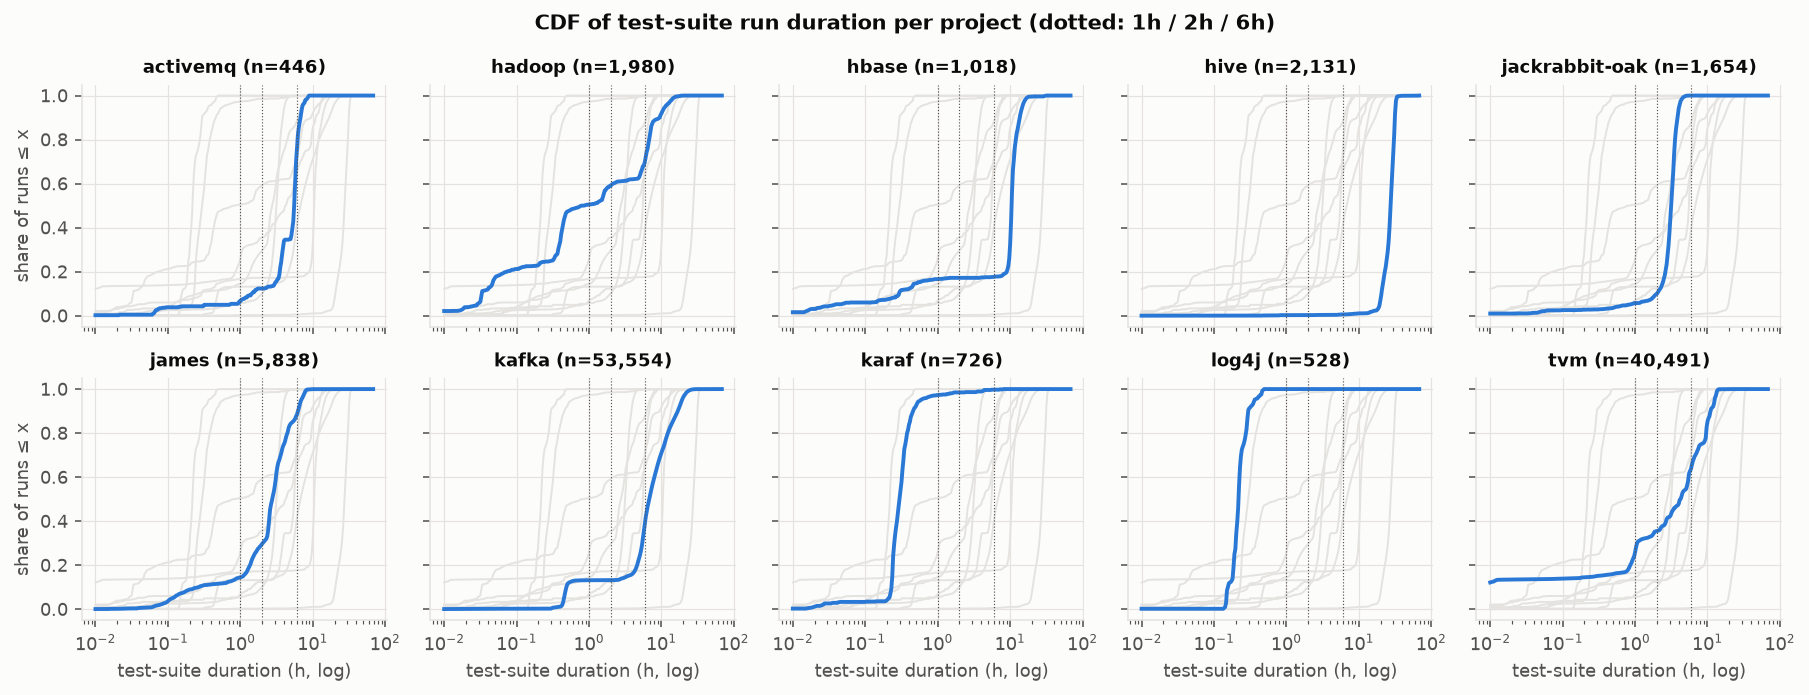

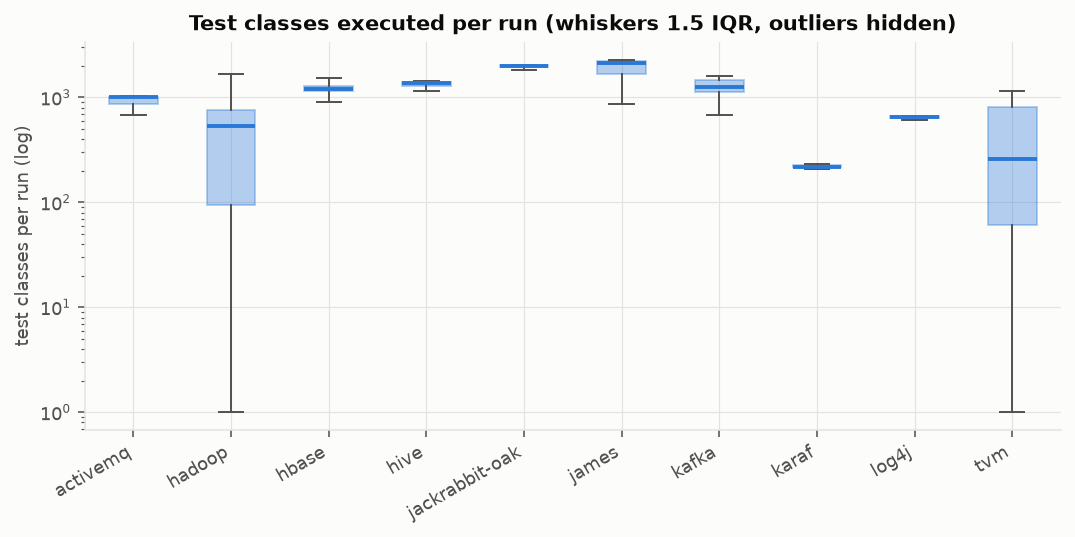

In [6]:
show('B_duration_cdf', 'B_classes_per_run')

## C. Dataset shape

In [7]:
s = c_shape.run()
pd.DataFrame(s['per_project'])

,project,runs,failed_runs,builds,failed_builds,stages,prs,paper_subset_runs,first_month,last_month,failed_run_rate,share_of_all_runs,share_of_paper_runs
0,activemq,446,197,446,197,1,262,207,2021-04,2024-04,0.441704,0.004116,0.003604
1,hadoop,1980,797,1980,797,1,935,1299,2020-07,2024-04,0.402525,0.018271,0.022616
2,hbase,1018,439,485,289,4,184,553,2022-03,2024-04,0.431238,0.009394,0.009628
3,hive,2131,1472,2131,1472,1,593,2056,2021-11,2024-03,0.690756,0.019665,0.035796
4,jackrabbit-oak,1654,1006,1654,1006,1,679,860,2021-07,2024-04,0.608222,0.015263,0.014973
5,james,5838,2528,4353,2528,2,1114,3147,2021-06,2024-04,0.433025,0.053873,0.054790
6,kafka,53554,37842,16088,14856,24,5414,39006,2020-11,2024-04,0.706614,0.494196,0.679109
7,karaf,726,205,726,205,1,528,620,2020-12,2024-04,0.282369,0.006700,0.010794
8,log4j,528,162,270,115,2,154,528,2020-11,2022-01,0.306818,0.004872,0.009193
9,tvm,40491,5026,6512,1972,19,1742,9161,2021-03,2024-04,0.124126,0.373650,0.159496


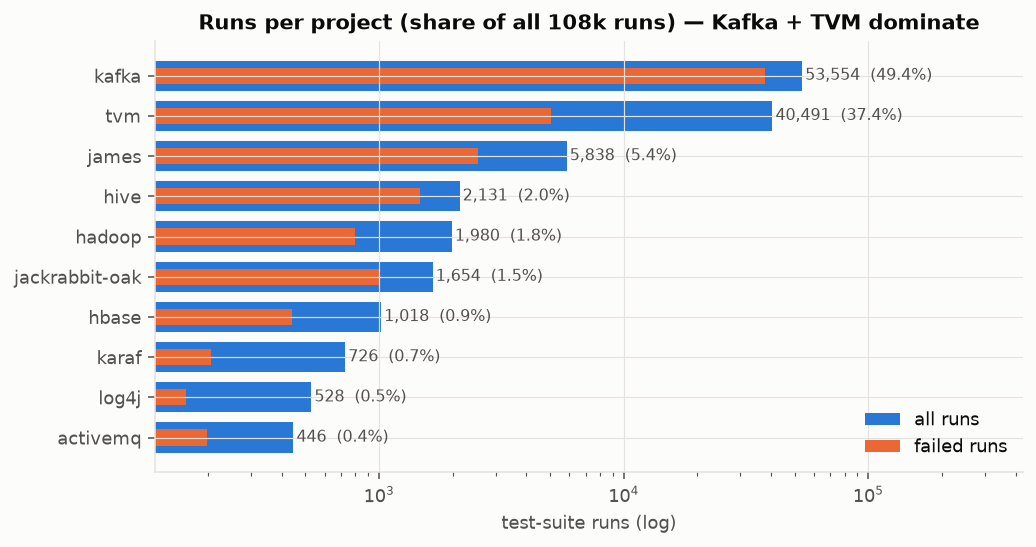

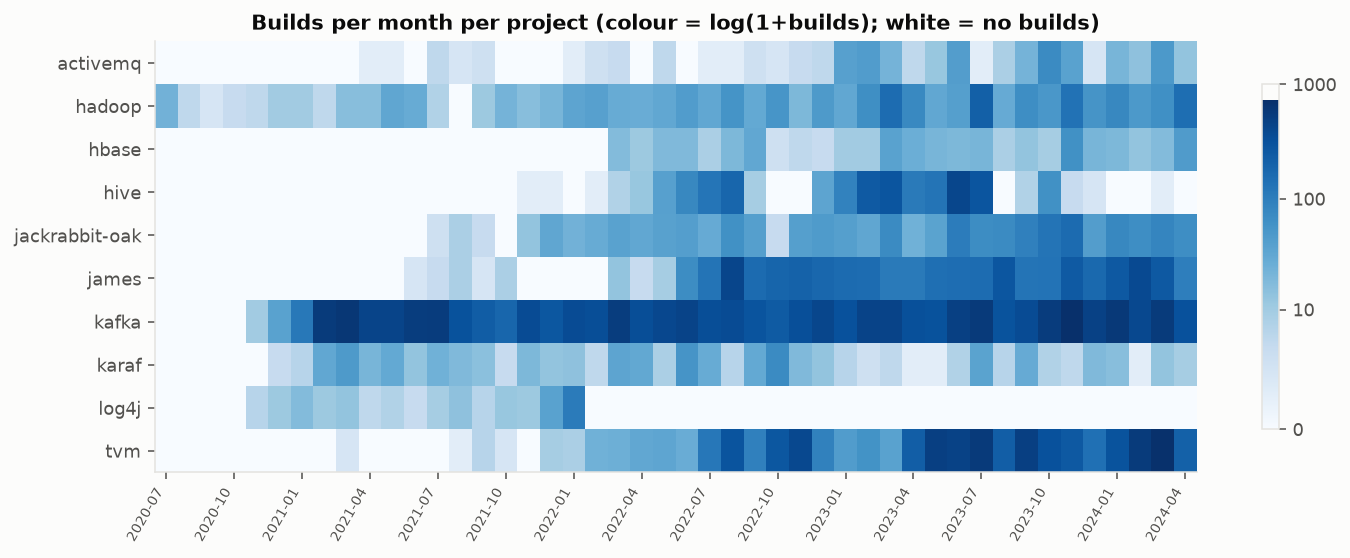

In [8]:
show('C_runs_per_project', 'C_builds_per_month')

## D. Failure structure

In [9]:
s = d_failures.run()
pd.DataFrame({k: s[k]['per_project'] for k in ['ftf_share_of_failures','ftf_share_of_failures_after_burn_in','failed_runs_with_any_ftf','failed_runs_all_ftf']}).round(3)

,ftf_share_of_failures,ftf_share_of_failures_after_burn_in,failed_runs_with_any_ftf,failed_runs_all_ftf
activemq,0.307,0.169,0.289,0.152
hadoop,0.268,0.128,0.235,0.087
hbase,0.515,0.500,0.538,0.355
hive,0.055,0.038,0.096,0.021
jackrabbit-oak,0.077,0.024,0.148,0.056
james,0.081,0.059,0.149,0.061
kafka,0.041,0.028,0.067,0.015
karaf,0.209,0.161,0.210,0.132
log4j,0.242,0.193,0.364,0.185
tvm,0.177,0.159,0.213,0.087


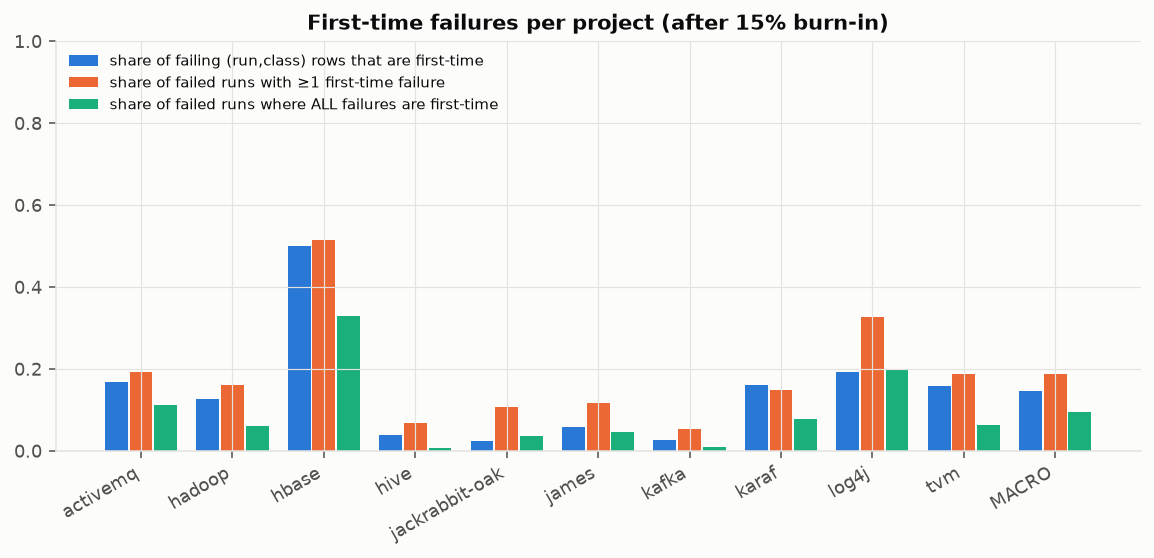

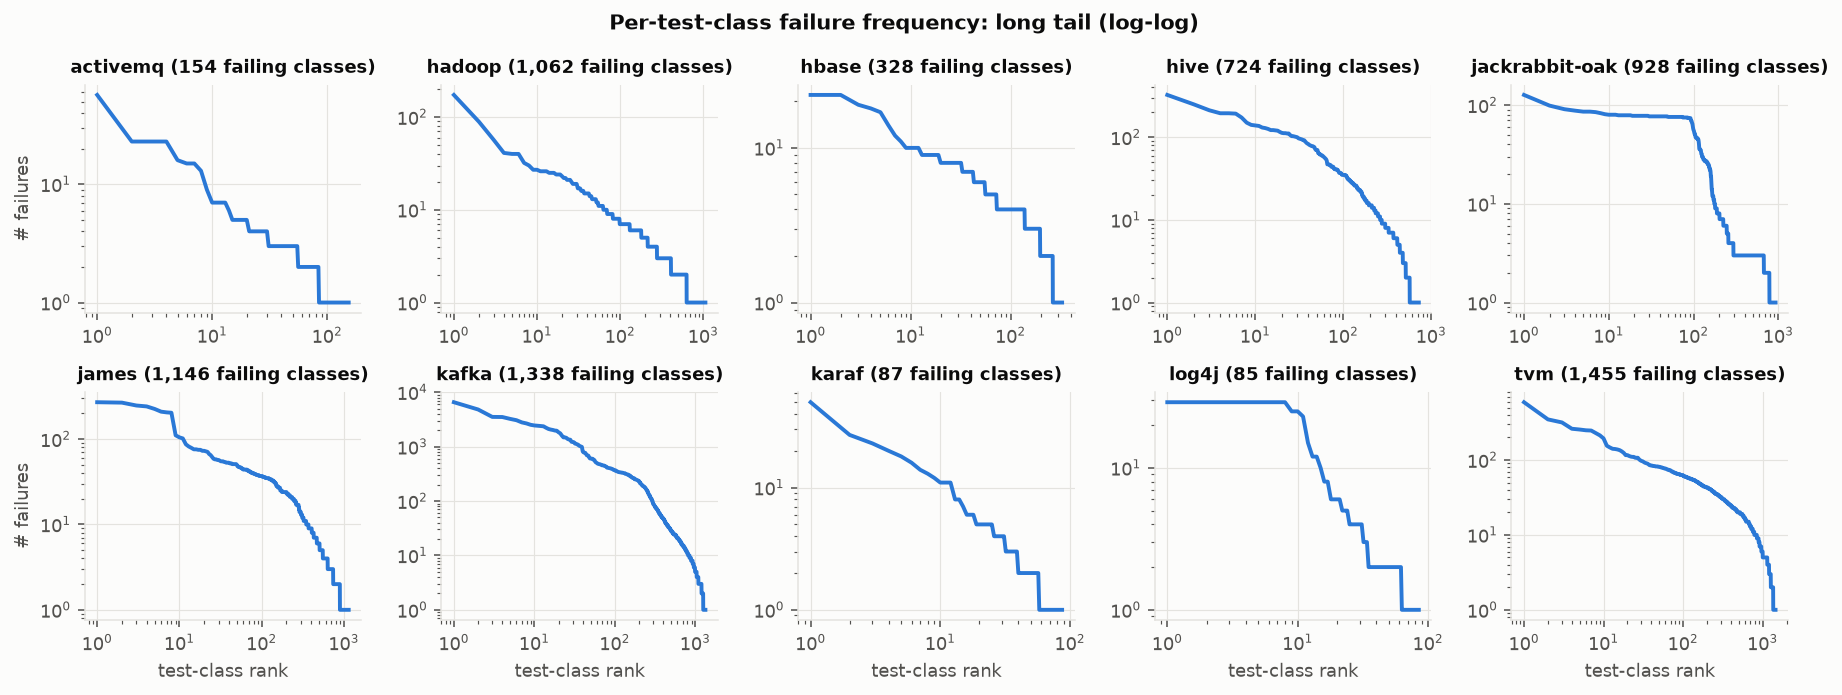

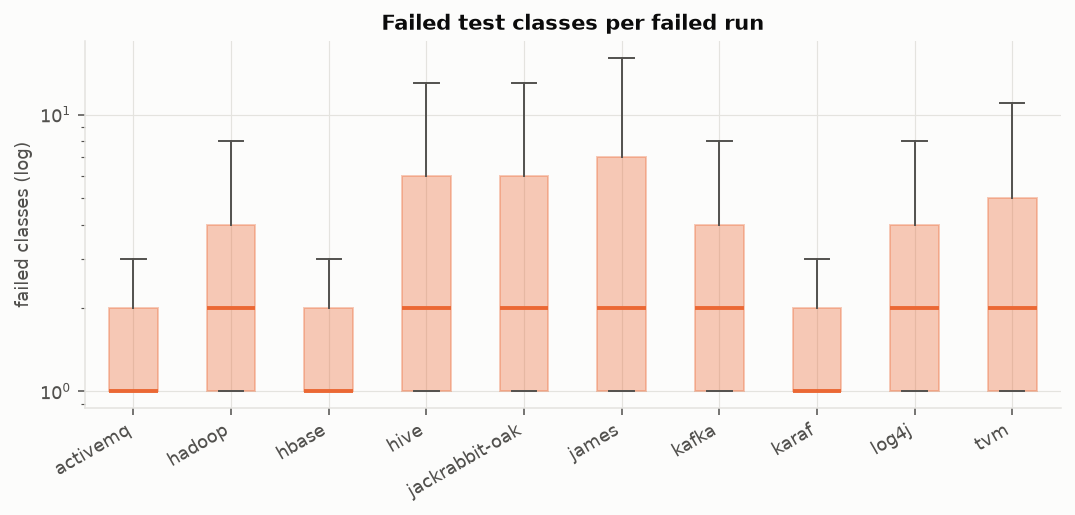

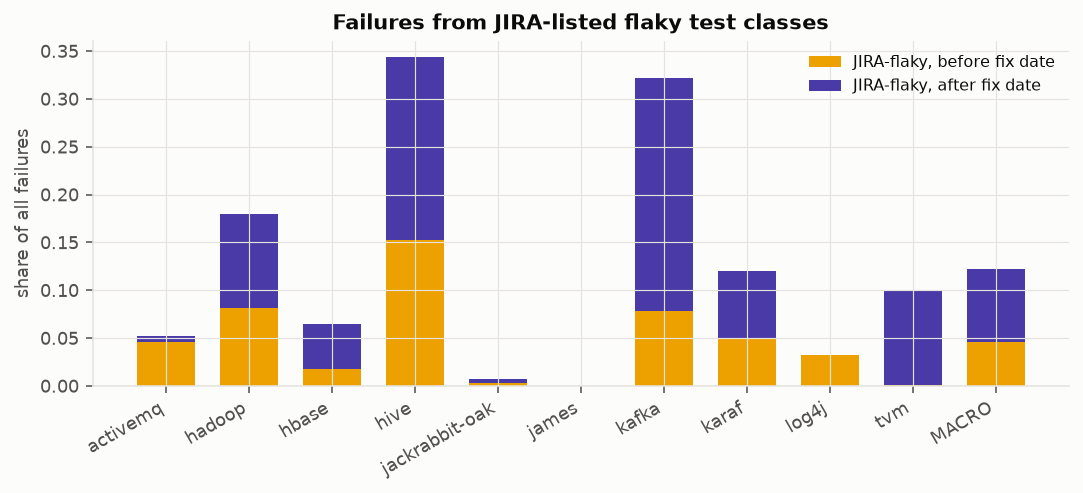

In [10]:
show('D_first_time_failures', 'D_failure_frequency_tail', 'D_failed_classes_per_run', 'D_flaky_share')

## E. Change data

In [11]:
s = e_changes.run()
pd.DataFrame({k: s[k]['per_project'] for k in ['files_per_build_median','lines_per_build_median','share_builds_with_patch_text','share_changed_files_with_patch']}).round(3)

,files_per_build_median,lines_per_build_median,share_builds_with_patch_text,share_changed_files_with_patch
activemq,2.0,18.0,0.998,0.994
hadoop,4.0,95.0,0.998,0.966
hbase,4.0,146.0,1.000,1.000
hive,6.0,241.0,1.000,0.809
jackrabbit-oak,4.0,118.0,0.999,0.998
james,7.0,164.0,1.000,0.965
kafka,4.0,140.0,0.998,0.908
karaf,1.0,2.0,1.000,0.913
log4j,3.0,79.0,1.000,0.955
tvm,4.0,150.0,1.000,0.952


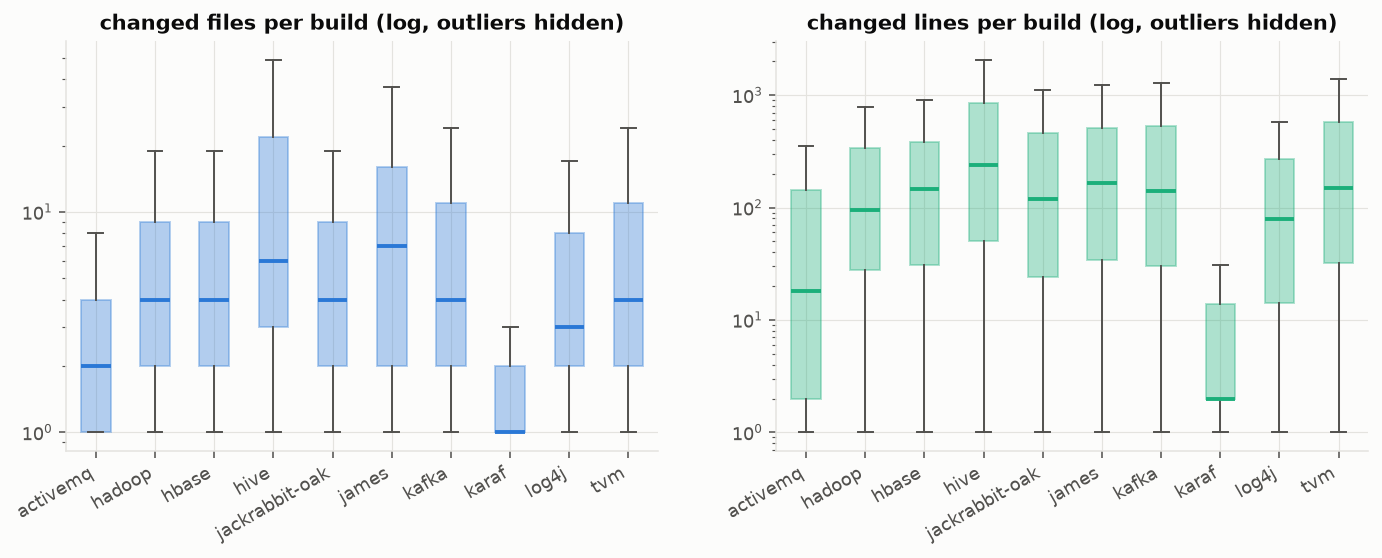

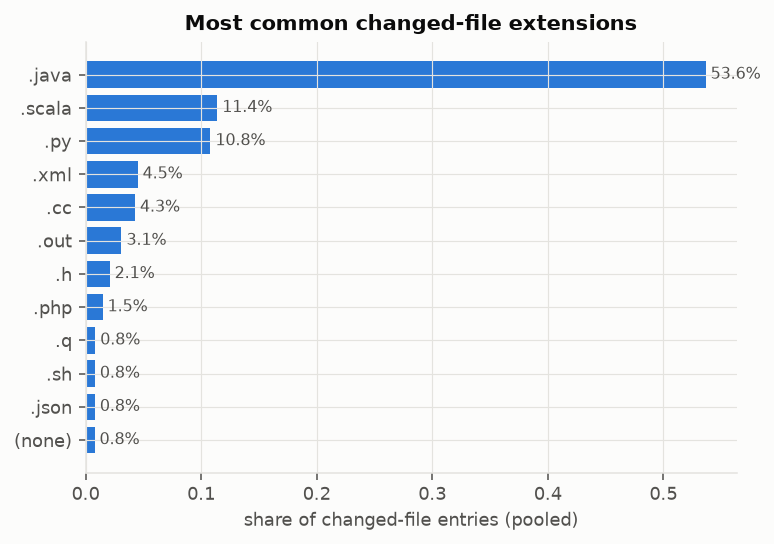

In [12]:
show('E_change_size', 'E_extensions')

## F. Is there a change signal? (token overlap lift)

In [13]:
s = f_signal.run()
pd.DataFrame({k: s[k]['per_project'] for k in ['lift_ftf_k1','lift_ftf_k2','lift_ftf_k3','lift_fail_k1','recall_ftf_k1','share_rows_overlap_ge1']}).round(3)

  [F] activemq: 379,243 rows, lift_ftf_k1=1.0214587535192634, 1s


  [F] hadoop: 1,154,052 rows, lift_ftf_k1=1.3561735072078984, 4s


  [F] hbase: 1,095,402 rows, lift_ftf_k1=2.05788343794031, 2s


  [F] hive: 2,758,143 rows, lift_ftf_k1=2.2527262113229782, 6s


  [F] jackrabbit-oak: 3,055,030 rows, lift_ftf_k1=0.9151692513207472, 4s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (8 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  [F] tvm: 16,249,532 rows, lift_ftf_k1=2.015693026861203, 20s


,lift_ftf_k1,lift_ftf_k2,lift_ftf_k3,lift_fail_k1,recall_ftf_k1,share_rows_overlap_ge1
activemq,1.021,1.618,6.917,0.776,0.110,0.108
hadoop,1.356,1.641,2.000,1.354,0.894,0.659
hbase,2.058,3.387,7.033,1.866,0.704,0.342
hive,2.253,3.489,3.974,2.004,0.555,0.246
jackrabbit-oak,0.915,1.467,2.725,0.848,0.310,0.339
james,1.692,2.872,5.682,1.354,0.586,0.347
kafka,2.297,5.261,10.265,1.404,0.648,0.282
karaf,3.282,4.165,8.735,2.879,0.414,0.126
log4j,0.995,2.051,5.553,0.976,0.866,0.871
tvm,2.016,3.897,6.491,1.991,0.674,0.334


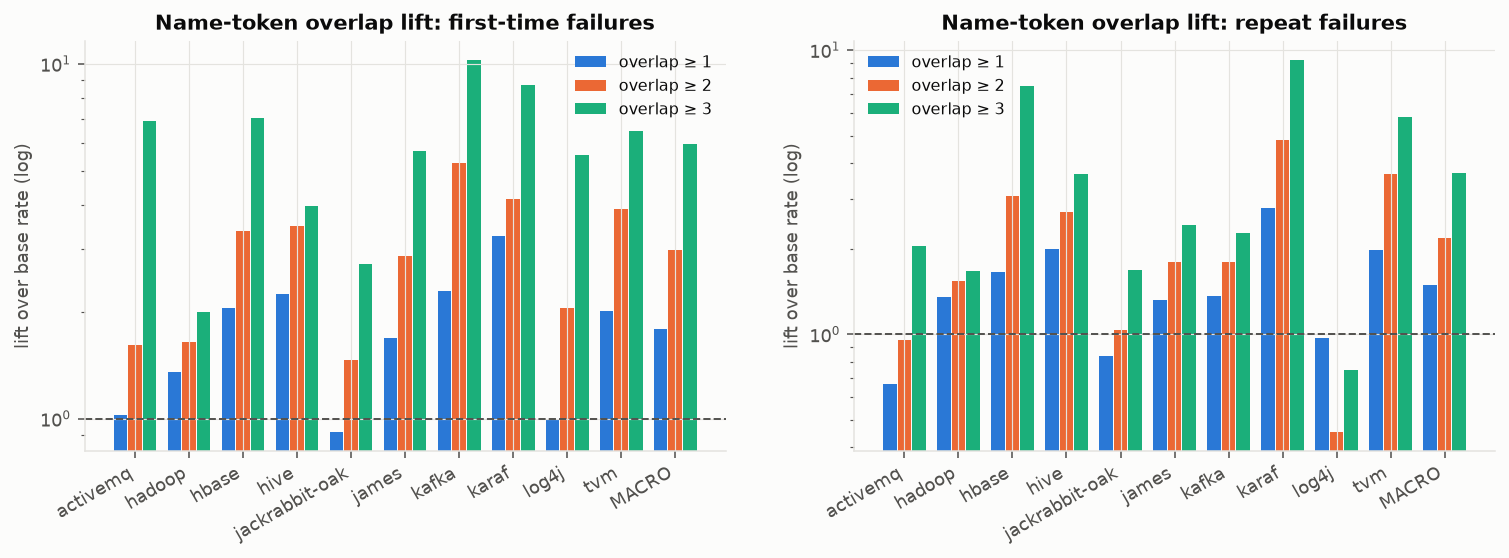

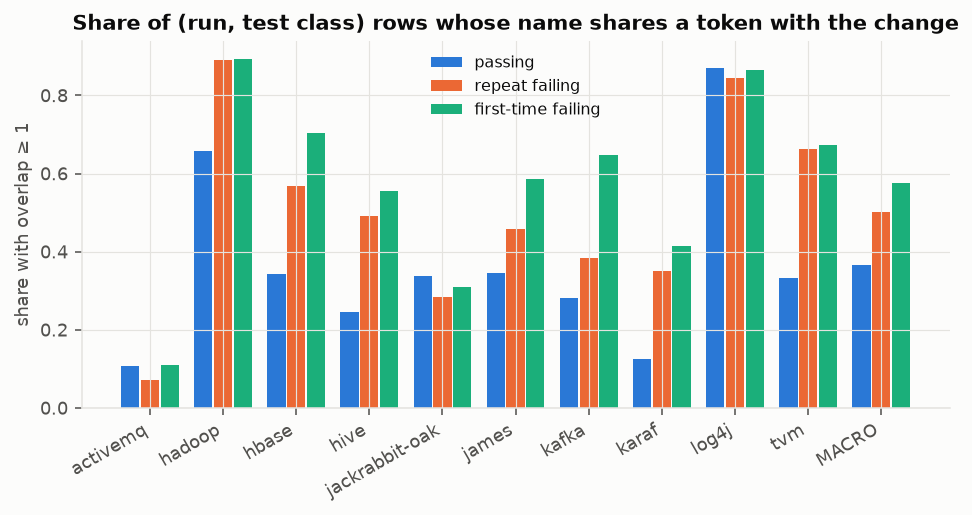

In [14]:
show('F_overlap_lift', 'F_overlap_share')

## G. Time to first failure (SAMPLE of <=300 failed runs/project)

In [15]:
s = g_ttff.run()
pd.DataFrame({k: s['all_failed_runs'][k]['per_project'] for k in ['median_min_Random','median_min_QTF','median_min_LastFail','median_min_Oracle','median_min_suite_s']}).round(1)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,median_min_Random,median_min_QTF,median_min_LastFail,median_min_Oracle,median_min_suite_s
activemq,110.9,51.7,8.1,0.6,327.8
hadoop,78.5,37.7,4.5,0.2,353.1
hbase,283.7,60.6,31.6,1.0,646.6
hive,580.7,342.1,100.5,3.8,1591.8
jackrabbit-oak,62.5,16.8,2.9,0.1,189.7
james,40.5,20.0,5.6,0.1,167.4
kafka,147.9,52.5,7.1,0.8,490.6
karaf,9.4,2.6,2.1,0.2,20.9
log4j,4.7,0.5,0.0,0.0,13.2
tvm,58.9,1.6,10.6,0.0,269.1


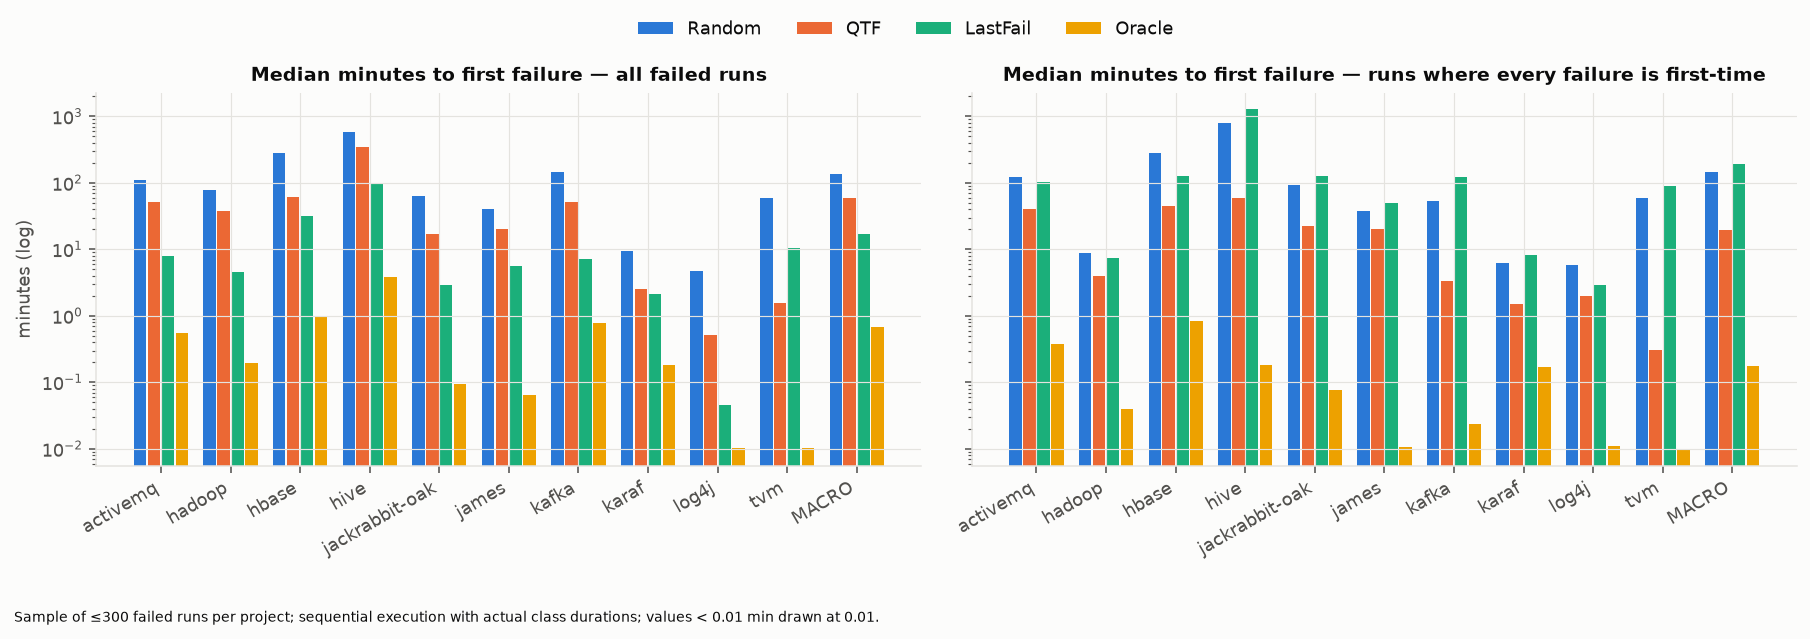

In [16]:
show('G_time_to_first_failure')

## H. Split feasibility (chronological 70/15/15)

In [17]:
s = h_split.run()
pd.DataFrame(s['table']).set_index(['project','split'])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

runs  failed_runs  ftf_runs  all_ftf_runs  failure_rate  mean_duration_h        from          to  distinct_test_classes  pct_test_classes_unseen_in_train
project        split                                                                                                                                                            
activemq       test      67           21         2             2      0.313433         5.471306  2024-02-27  2024-04-12                   1029                          0.003887
               train    312          145        50            26      0.464744         4.647771  2021-04-01  2023-11-06                   1120                               NaN
               val       67           31         5             2      0.462687         5.108924  2023-11-06  2024-02-27                   1043                               NaN
hadoop         test     297          107        10             3      0.360269         3.366471  2024-01-16  2024-04-16                   3003                          0.013986
               train   1386          566       164            61      0.408369         3.273934  2020-07-30  2023-09-19                   3142                               NaN
               val      297          124        13             5      0.417508         3.541565  2023-09-22  2024-01-15                   2978                               NaN
hbase          test     152           58        26            18      0.381579        11.265155  2024-03-21  2024-04-16                   1898                          0.014226
               train    713          311       178           120      0.436185         8.806599  2022-03-11  2023-11-27                   1927                               NaN
               val      153           70        32            18      0.457516        10.316737  2023-11-28  2024-03-21                   1881                               NaN
hive           test     320          184        14             3      0.575000        27.058340  2023-07-07  2024-03-12                   1604                          0.031796
               train   1492         1112       125            28      0.745308        25.971139  2021-11-18  2023-06-09                   1610                               NaN
               val      319          176         3             0      0.551724        29.563657  2023-06-09  2023-07-07                   1490                               NaN
jackrabbit-oak test     248          154         9             5      0.620968         3.174592  2024-01-22  2024-04-16                   2085                          0.014868
               train   1158          767       127            48      0.662349         2.989462  2021-07-13  2023-11-01                   2126                               NaN
               val      248           85        13             3      0.342742         2.848515  2023-11-02  2024-01-22                   2059                               NaN
james          test     876          320        28            11      0.365297         4.089894  2024-02-08  2024-04-16                   2538                          0.079984
               train   4086         1869       308           131      0.457416         2.917411  2021-06-02  2023-11-23                   2588                               NaN
               val      876          339        41            13      0.386986         2.483457  2023-11-23  2024-02-08                   2528                               NaN
kafka          test    8031         7816       220             3      0.973229        15.397894  2023-11-30  2024-04-16                   1792                          0.136719
               train  37488        22625      1856           551      0.603526         5.977624  2020-11-16  2023-07-07                   2145                               NaN
               val     8035         7401       471            23      0.921095        11.115305  2023-07-07  2023-11-30          

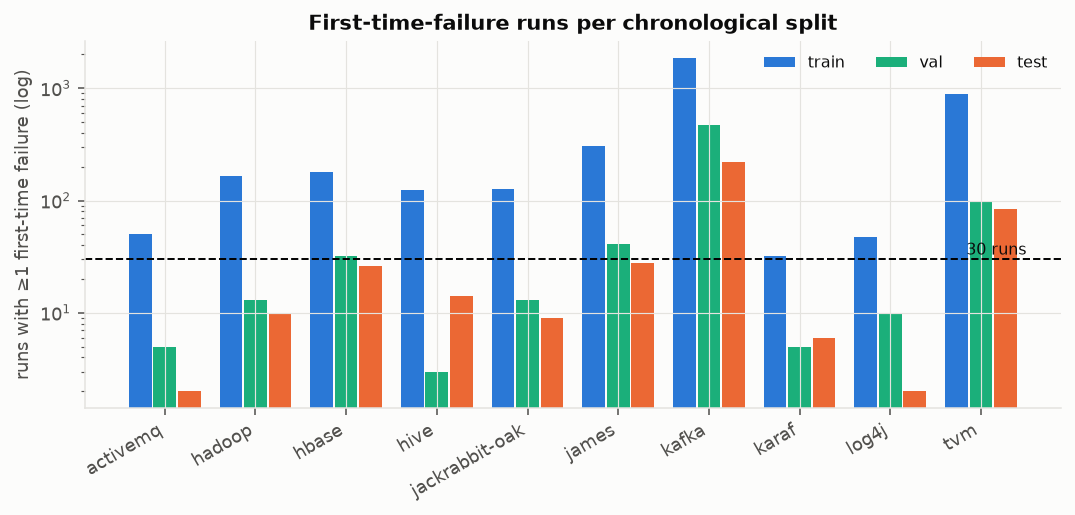

In [18]:
show('H_split_ftf_runs')